In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Bank_Personal_Loan_Modelling.csv to Bank_Personal_Loan_Modelling (1).csv


In [ ]:
import pandas as pd

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print(df.shape)
display(df.head())

(5000, 14)


,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,1,25,1,49,91107,4,1.6,1,0,0,1,0,0,0
1,2,45,19,34,90089,3,1.5,1,0,0,1,0,0,0
2,3,39,15,11,94720,1,1.0,1,0,0,0,0,0,0
3,4,35,9,100,94112,1,2.7,2,0,0,0,0,0,0
4,5,35,8,45,91330,4,1.0,2,0,0,0,0,0,1


In [ ]:
import os

print(os.listdir())

['.config', 'Bank_Personal_Loan_Modelling.csv', 'Bank_Personal_Loan_Modelling (1).csv', 'sample_data']


### Step 1: Inspecting the Dataset

In [ ]:
print(df.info())
print(df.isnull().sum())
print(df.duplicated().sum())
display(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   ID                  5000 non-null   int64  
 1   Age                 5000 non-null   int64  
 2   Experience          5000 non-null   int64  
 3   Income              5000 non-null   int64  
 4   ZIP Code            5000 non-null   int64  
 5   Family              5000 non-null   int64  
 6   CCAvg               5000 non-null   float64
 7   Education           5000 non-null   int64  
 8   Mortgage            5000 non-null   int64  
 9   Personal Loan       5000 non-null   int64  
 10  Securities Account  5000 non-null   int64  
 11  CD Account          5000 non-null   int64  
 12  Online              5000 non-null   int64  
 13  CreditCard          5000 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 547.0 KB
None
ID                    0
Age                   0
Exp

,ID,Age,Experience,Income,ZIP Code,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,2500.500000,45.338400,20.104600,73.774200,93152.503000,2.396400,1.937938,1.881000,56.498800,0.096000,0.104400,0.06040,0.596800,0.294000
std,1443.520003,11.463166,11.467954,46.033729,2121.852197,1.147663,1.747659,0.839869,101.713802,0.294621,0.305809,0.23825,0.490589,0.455637
min,1.000000,23.000000,-3.000000,8.000000,9307.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
25%,1250.750000,35.000000,10.000000,39.000000,91911.000000,1.000000,0.700000,1.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000
50%,2500.500000,45.000000,20.000000,64.000000,93437.000000,2.000000,1.500000,2.000000,0.000000,0.000000,0.000000,0.00000,1.000000,0.000000
75%,3750.250000,55.000000,30.000000,98.000000,94608.000000,3.000000,2.500000,3.000000,101.000000,0.000000,0.000000,0.00000,1.000000,1.000000
max,5000.000000,67.000000,43.000000,224.000000,96651.000000,4.000000,10.000000,3.000000,635.000000,1.000000,1.000000,1.00000,1.000000,1.000000


### Step 2: Drop Unnecessary Columns

In [ ]:
df_cleaned = df.drop(columns=['ID', 'ZIP Code'])
display(df_cleaned.head())

,Age,Experience,Income,Family,CCAvg,Education,Mortgage,Personal Loan,Securities Account,CD Account,Online,CreditCard
0,25,1,49,4,1.6,1,0,0,1,0,0,0
1,45,19,34,3,1.5,1,0,0,1,0,0,0
2,39,15,11,1,1.0,1,0,0,0,0,0,0
3,35,9,100,1,2.7,2,0,0,0,0,0,0
4,35,8,45,4,1.0,2,0,0,0,0,0,1


### Step 3: Split Features and Target, and Perform Train-Test Split

In [ ]:
from sklearn.model_selection import train_test_split

X = df_cleaned.drop(columns=['Personal Loan'])
y = df_cleaned['Personal Loan']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(4000, 11) (1000, 11)


### Step 4: Feature Scaling

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Step 5: Train and Evaluate Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

lr_model = LogisticRegression()
lr_model.fit(X_train_scaled, y_train)

lr_preds = lr_model.predict(X_test_scaled)
lr_acc = accuracy_score(y_test, lr_preds)

print(lr_acc)
print(confusion_matrix(y_test, lr_preds))
print(classification_report(y_test, lr_preds))

0.955
[[891  13]
 [ 32  64]]
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       904
           1       0.83      0.67      0.74        96

    accuracy                           0.95      1000
   macro avg       0.90      0.83      0.86      1000
weighted avg       0.95      0.95      0.95      1000



### Step 6: Train and Evaluate Support Vector Machine (SVM)

In [ ]:
from sklearn.svm import SVC

svm_model = SVC()
svm_model.fit(X_train_scaled, y_train)

svm_preds = svm_model.predict(X_test_scaled)
svm_acc = accuracy_score(y_test, svm_preds)

print(svm_acc)
print(confusion_matrix(y_test, svm_preds))
print(classification_report(y_test, svm_preds))

0.978
[[902   2]
 [ 20  76]]
              precision    recall  f1-score   support

           0       0.98      1.00      0.99       904
           1       0.97      0.79      0.87        96

    accuracy                           0.98      1000
   macro avg       0.98      0.89      0.93      1000
weighted avg       0.98      0.98      0.98      1000



### Step 7: Compare Model Performance

In [ ]:
comparison_df = pd.DataFrame({
    'Model': ['Logistic Regression', 'Support Vector Machine'],
    'Accuracy': [lr_acc, svm_acc]
})
display(comparison_df)

,Model,Accuracy
0,Logistic Regression,0.955
1,Support Vector Machine,0.978


### Step 8: Visualizations

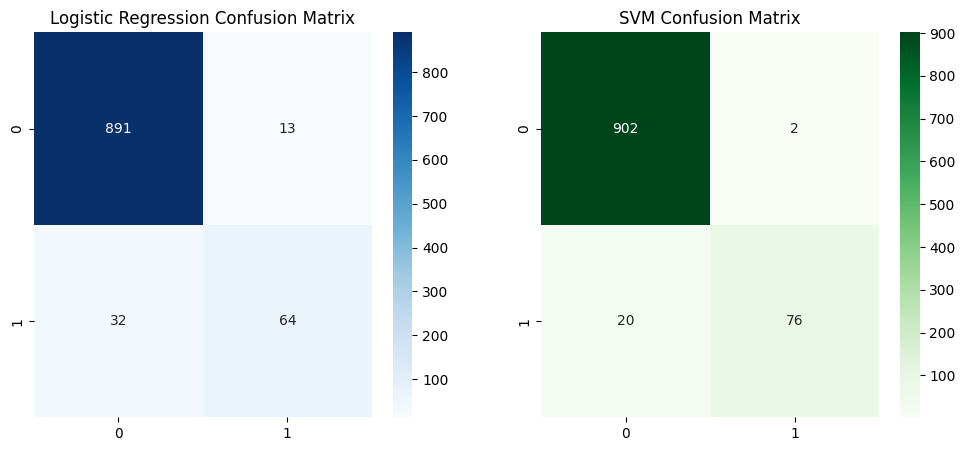

/tmp/ipykernel_5262/3477970833.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=comparison_df, palette='Set2')


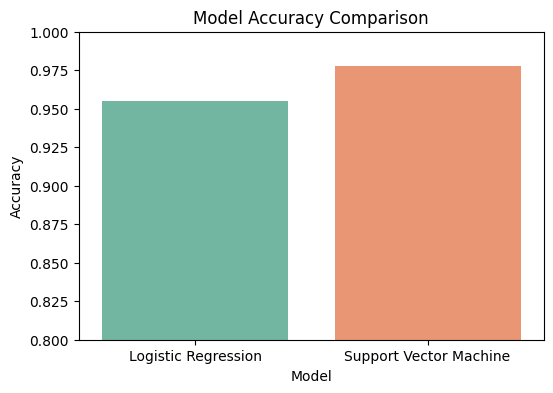

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(confusion_matrix(y_test, lr_preds), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Logistic Regression Confusion Matrix')

sns.heatmap(confusion_matrix(y_test, svm_preds), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title('SVM Confusion Matrix')
plt.show()

plt.figure(figsize=(6, 4))
sns.barplot(x='Model', y='Accuracy', data=comparison_df, palette='Set2')
plt.ylim(0.8, 1.0)
plt.title('Model Accuracy Comparison')
plt.show()

### Step 9: Final Conclusion Summary

Conclusion for Assignment:

We successfully implemented both Supervised Learning models for the Bank Personal Loan Modelling project.
After cleaning the features, scaling the dataset, and performing stratified splits, we evaluated both models.
- Logistic Regression Accuracy: 0.9550
- Support Vector Machine Accuracy: 0.9780
The Support Vector Machine performed better on our test dataset with an overall accuracy of 0.9780.